<a href="https://colab.research.google.com/github/zyamjadoon1/DATA201-LABS/blob/main/Week8_HW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DATA 201 - Week 8 Homework: Finding the Right Amount of Regularization

**Name:** Zyam Khawaja
**Dataset:** Hitters (from the ISLP library)
**Goal:** Investigate how the strength of regularization (alpha) affects model performance, complexity, and interpretability using Lasso regression.

In [1]:
# Install ISLP
try:
    import ISLP
except ImportError:
    %pip install -q ISLP

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## Setup: load and prepare the data

- Drop players with a missing `Salary` (the response variable).
- Turn the categorical columns (`League`, `Division`, `NewLeague`) into 0/1 dummy variables.
- Split into training (70%) and test (30%) sets.
- Standardize the predictors using the **training** set only. Lasso penalizes the size of coefficients, so predictors must be on the same scale.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ISLP import load_data
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error

Hitters = load_data("Hitters")
print("Rows before dropping missing values:", Hitters.shape[0])
Hitters = Hitters.dropna()
print("Rows after dropping missing values: ", Hitters.shape[0])

y = Hitters["Salary"]
X = pd.get_dummies(Hitters.drop(columns="Salary"), drop_first=True).astype(float)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

print("Training rows:", X_train.shape[0], "| Test rows:", X_test.shape[0], "| Predictors:", X.shape[1])

Rows before dropping missing values: 322
Rows after dropping missing values:  263
Training rows: 184 | Test rows: 79 | Predictors: 19


## Part 1 - Experiment with alpha

Fit three Lasso models with `alpha_values = [0.1, 10, 100]` and report the training RMSE, test RMSE, and number of nonzero coefficients for each. (Salary is measured in thousands of dollars, so an RMSE of 340 means about $340,000.)

In [3]:
alpha_values = [0.1, 10, 100]

rows = []
models = {}
for a in alpha_values:
    lasso = Lasso(alpha=a, max_iter=100000).fit(X_train_s, y_train)
    models[a] = lasso
    train_rmse = np.sqrt(mean_squared_error(y_train, lasso.predict(X_train_s)))
    test_rmse = np.sqrt(mean_squared_error(y_test, lasso.predict(X_test_s)))
    rows.append({
        "Alpha": a,
        "Training RMSE": round(train_rmse, 2),
        "Test RMSE": round(test_rmse, 2),
        "Nonzero coefficients": int((lasso.coef_ != 0).sum()),
    })

results = pd.DataFrame(rows)
results

,Alpha,Training RMSE,Test RMSE,Nonzero coefficients
0,0.1,293.66,352.91,19
1,10.0,317.80,340.03,9
2,100.0,356.04,373.05,5


### Part 1 - Questions

**1. As alpha increases, what happens to the number of retained predictors?**

The number of retained predictors goes down. With alpha = 0.1 the Lasso keeps all 19 predictors, with alpha = 10 it keeps 9, and with alpha = 100 it keeps only 5. A larger alpha puts a bigger penalty on the size of the coefficients, so more of them are pushed all the way to zero.

**2. Does a smaller number of predictors always lead to a lower test RMSE?**

No. Going from 19 predictors (alpha = 0.1, test RMSE 352.91) to 9 predictors (alpha = 10, test RMSE 340.03) lowered the test RMSE. But going down to 5 predictors (alpha = 100) raised the test RMSE to 373.05, which is the worst of the three. Removing predictors helps only until the model starts losing useful information. After that it underfits and predicts worse.

## Part 2 - Visualize and interpret

Graph of alpha versus test RMSE for the three models.

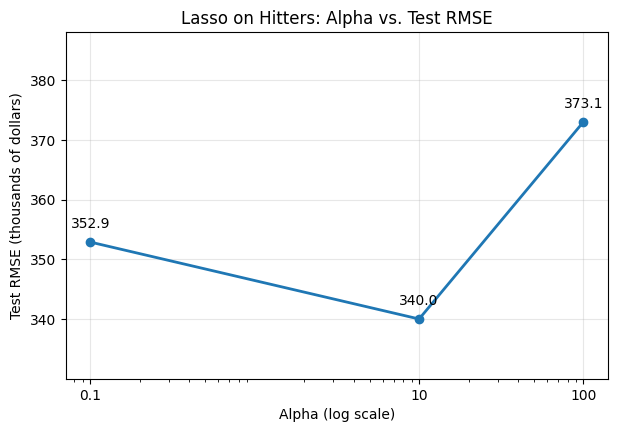

In [4]:
plt.figure(figsize=(7, 4.5))
plt.plot(results["Alpha"], results["Test RMSE"], marker="o", linewidth=2, color="tab:blue")
for _, r in results.iterrows():
    plt.annotate(f"{r['Test RMSE']:.1f}", (r["Alpha"], r["Test RMSE"]),
                 textcoords="offset points", xytext=(0, 10), ha="center")
plt.xscale("log")
plt.ylim(min(results["Test RMSE"]) - 10, max(results["Test RMSE"]) + 15)
plt.xticks(alpha_values, [str(a) for a in alpha_values])
plt.xlabel("Alpha (log scale)")
plt.ylabel("Test RMSE (thousands of dollars)")
plt.title("Lasso on Hitters: Alpha vs. Test RMSE")
plt.grid(alpha=0.3)
plt.show()

### Part 2 - Questions

**1. Which alpha produces the lowest test RMSE among the three values?**

Alpha = 10 produces the lowest test RMSE (340.03), compared with 352.91 for alpha = 0.1 and 373.05 for alpha = 100.

**2. Which alpha appears to cause the most underfitting? Explain using bias.**

Alpha = 100 causes the most underfitting. The penalty is so strong that 14 of the 19 coefficients are forced to zero and the remaining ones are shrunk a lot, so the model is too simple to capture the real relationship between the predictors and salary. That is high bias: the model's predictions are systematically off, no matter which data it sees. It shows up as the highest error on both the training data (RMSE 356.04) and the test data (RMSE 373.05).

**3. Why might a model with higher training RMSE produce lower test RMSE?**

Training RMSE only measures how well the model fits the data it was trained on, and a model can fit that data too closely by memorizing noise (overfitting). Regularization adds some bias, so the training RMSE goes up, but it also lowers variance, so the model depends less on the noise in the training set. Here alpha = 10 has a higher training RMSE (317.80) than alpha = 0.1 (293.66), but a lower test RMSE (340.03 vs 352.91), so it generalizes better to new players.

## Part 3 - Model interpretation

Using the results from Part 1, look at which coefficients each model set to zero.

In [5]:
coef_table = pd.DataFrame(
    {f"alpha = {a}": models[a].coef_ for a in alpha_values},
    index=X.columns,
)
print("Coefficients (standardized predictors):")
display(coef_table.round(2))

zeroed_100 = list(coef_table.index[coef_table["alpha = 100"] == 0])
kept_100 = list(coef_table.index[coef_table["alpha = 100"] != 0])
print("Set to zero at alpha = 100 (", len(zeroed_100), "):", zeroed_100)
print("Kept at alpha = 100 (", len(kept_100), "):", kept_100)

print()
print("Correlation between a zeroed predictor (CAtBat) and the kept ones:")
print(X[["CAtBat", "CHits", "CRBI", "Hits"]].corr().round(2))

Coefficients (standardized predictors):


,alpha = 0.1,alpha = 10,alpha = 100
AtBat,-325.51,-21.24,0.00
Hits,346.43,109.70,41.28
HmRun,-25.18,-0.00,0.00
Runs,-57.05,-0.00,0.00
RBI,56.65,0.00,19.96
Walks,127.65,46.51,17.53
Years,30.06,-0.00,0.00
CAtBat,-753.93,0.00,0.00
CHits,696.61,0.00,0.00
CHmRun,170.52,33.36,0.00


Set to zero at alpha = 100 ( 14 ): ['AtBat', 'HmRun', 'Runs', 'Years', 'CAtBat', 'CHits', 'CHmRun', 'CRuns', 'CWalks', 'Assists', 'Errors', 'League_N', 'Division_W', 'NewLeague_N']
Kept at alpha = 100 ( 5 ): ['Hits', 'RBI', 'Walks', 'CRBI', 'PutOuts']

Correlation between a zeroed predictor (CAtBat) and the kept ones:
        CAtBat  CHits  CRBI  Hits
CAtBat    1.00   1.00  0.95  0.21
CHits     1.00   1.00  0.95  0.24
CRBI      0.95   0.95  1.00  0.22
Hits      0.21   0.24  0.22  1.00


### Part 3 - Questions

**1. Identify two predictors that Lasso sets to zero at alpha = 100.**

`CAtBat` (career at-bats) and `CHits` (career hits) are both set to zero at alpha = 100. (Others set to zero include `AtBat`, `Runs`, `Years`, and `HmRun`.) The Lasso keeps only five predictors at this alpha: `Hits`, `RBI`, `Walks`, `CRBI`, and `PutOuts`.

**2. Does setting their coefficients to zero prove that these predictors have no relationship with salary? Explain.**

No. A zero coefficient only means the model did not need that predictor once the other predictors and the penalty were taken into account. `CAtBat` and `CHits` are almost perfectly correlated with each other (about 1.00) and are also highly correlated with `CRBI` (about 0.95), which the Lasso kept. When predictors carry the same information, the Lasso tends to keep one and drop the others, so a dropped predictor can still be related to salary. A zero also depends on the size of alpha: both `CAtBat` and `CHits` have nonzero coefficients at alpha = 0.1, but they are dropped when the penalty is large. So a zero coefficient means "not needed in this model," not "no relationship."

**3. If two models have very similar test RMSE but one uses fewer predictors, which would you prefer? Explain in terms of interpretability and predictive performance.**

I would prefer the model with fewer predictors. If the test RMSE is about the same, the two models predict equally well, so the simpler one costs nothing in predictive performance. The simpler model is easier to interpret and explain because there are fewer variables to look at. It is also less likely to be overfitting, so it is more likely to keep working on new data, and it is cheaper to collect and maintain.

## Part 4 - Choosing the right regression model

**Scenario A - Lasso (L1).**
The researcher has 200 measurements but only 80 patients, so there are more predictors than observations. Ordinary least squares can overfit badly or fail outright in that situation. The goal is to identify a small number of useful measurements, and Lasso is the method that sets many coefficients exactly to zero, so the measurements it keeps are the small, interpretable set the researcher wants.

**Scenario B - Ridge (L2).**
With 40 predictors that are strongly correlated and most believed to be useful, there is no need to drop any of them. Ridge shrinks the coefficients of correlated predictors together and keeps them all in the model, which stabilizes the estimates and reduces overfitting. Lasso would arbitrarily drop some of the correlated predictors that the company thinks are useful.

**Scenario C - Ordinary Linear Regression.**
With 10,000 observations and only three predictors, overfitting is not a real risk, so there is little for regularization to fix. The relationship looks linear and the researcher wants a simple, easy-to-interpret model, and ordinary least squares gives the most direct interpretation, with a coefficient for each predictor that is not shrunk.

**Scenario D - Not Sure.**
With 500 observations and 25 predictors, it is unclear how many predictors are useful or how correlated they are, and the company wants the most accurate predictions. Ridge, Lasso, or ordinary regression could each win, depending on the data. The right approach is to use cross-validation to compare the models (and tune alpha for Ridge and Lasso), then pick the one with the lowest cross-validated test error.